In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, vectorize

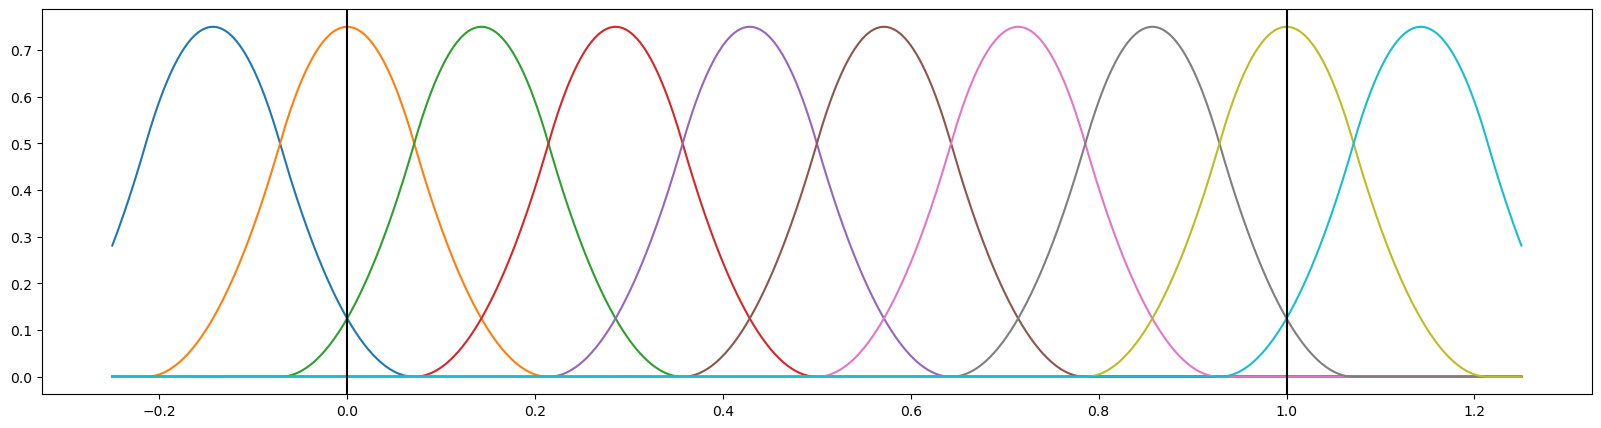

In [9]:
@vectorize
def _bspline3_kernel(x):
    res = 0.0
    if x < 0:
        return 0
    elif x < 1:
        return 0.5 * x**2
    elif x < 2:
        return 0.5 * (-2*x**2 + 6*x - 3)
    elif x < 3:
        return 0.5 * (x-3)**2
    else:
        return 0

@njit(inline='always')
def bspline3(X, params):
    N = params.shape[0]
    window_size = N - 3
    X = window_size * X

    res = np.zeros_like(X)
    for i in range(N):
        res += params[i] * _bspline3_kernel(X - i + 2.5)

    return res

x = np.linspace(-0.25, 1.25, 1000)

n_free_params = 10
nparams = (n_free_params+1)*4 + 3

plt.figure(figsize=(20, 5))

for n in range(n_free_params):
    zero = np.array([0.])
    params = np.zeros(n_free_params)
    params[n] = 1
    #params_fl = np.flip(params)
    #params = np.concatenate((zero, params_fl, zero, params, zero, params_fl, params, zero ))
    y = bspline3(x, params)
    plt.plot(x, y)

plt.axvline(0, color='black')
plt.axvline(1, color='black')
#plt.axvline(0.25, color='black', linestyle='--')
#plt.axvline(0.5, color='black', linestyle='--')
#plt.axvline(0.75, color='black', linestyle='--')

In [206]:
bspline3(3.5, params)

array(0.)